## 1. Import Libraries, Configuration, and Utilities
Here we import libraries, and define constants used
throughout the notebook. We also define utility functions for model.

### 1.1. Import Libraries

In [1]:
# Import necessary libraries
import matplotlib.pyplot as plt
# NLP and preprocessing
import nltk
import numpy as np
import pandas as pd
# Deep learning
import torch
# Machine learning
from sklearn.metrics import (classification_report, hamming_loss, f1_score, jaccard_score)
from transformers import AutoTokenizer, AutoModelForSequenceClassification

/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Download necessary NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('stopwords')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /Users/hsamadov/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [3]:
# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### 1.2. Configuration Parameters

In [4]:
TEST_DATA_PATH = 'data/track-a-test.csv'

In [5]:
# Emotion labels we're predicting
EMOTIONS = ['anger', 'fear', 'joy', 'sadness', 'surprise']

In [6]:
# Define model paths and data path
MODELS = {
    'roberta-base': './results/roberta-base_vanilla_out',
    'bert-base': './results/bert-base-uncased_vanilla_out',
    'distilbert-base': './results/distilbert-base-uncased_vanilla_out',
    'twitter-roberta': './results/twitter-roberta-base-emotion-multilabel-latest_vanilla_out'
}

## 2. Data Loading & Quick EDA

In [7]:
# Load the dataset
df = pd.read_csv(TEST_DATA_PATH)

# Display the first few rows to understand the data structure
df.head()

,id,text,anger,fear,joy,sadness,surprise
0,eng_dev_track_a_00001,Older sister (23 at the time) is a Scumbag Stacy.,1,0,0,0,0
1,eng_dev_track_a_00002,"And I laughed like this: garhahagar, because m...",0,1,0,0,0
2,eng_dev_track_a_00003,It overflowed and brown shitty diarrhea water ...,1,1,0,1,1
3,eng_dev_track_a_00004,Its very dark and foggy.,0,1,0,0,0
4,eng_dev_track_a_00005,"Then she tried to, like, have sex with/strangl...",1,1,0,0,1


In [8]:
texts = df['text'].tolist()

## 4. Model Comparison

In [9]:
def compute_metrics(y_true, y_pred, threshold=0.5, verbose=False):
    if not isinstance(y_pred[0][0], (np.int64, np.int32, int, bool)):
        y_pred_binary = (y_pred >= threshold).astype(int)
    else:
        y_pred_binary = y_pred

    metrics = {
        "hamming_loss": hamming_loss(y_true, y_pred_binary),
        "exact_match": np.all(y_true == y_pred_binary, axis=1).mean(),
        "f1_micro": f1_score(y_true, y_pred_binary, average="micro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred_binary, average="macro", zero_division=0),
        "jaccard_micro": jaccard_score(y_true, y_pred_binary, average="micro", zero_division=0),
        "jaccard_macro": jaccard_score(y_true, y_pred_binary, average="macro", zero_division=0)
    }

    if verbose:
        print(classification_report(y_true, y_pred_binary, target_names=EMOTIONS, zero_division=0))
        print(f"Exact Match Accuracy: {metrics['exact_match']:.4f}")

    return metrics

In [10]:
def predict(model_dir, texts, batch_size=32):
    tokenizer = AutoTokenizer.from_pretrained(model_dir)
    model = AutoModelForSequenceClassification.from_pretrained(model_dir)
    model.to(device)
    model.eval()

    all_preds = []

    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch_texts = texts[i:i+batch_size]
            encodings = tokenizer(batch_texts, padding=True, truncation=True, return_tensors="pt").to(device)
            outputs = model(**encodings)
            logits = outputs.logits
            probs = torch.sigmoid(logits).cpu().numpy()
            all_preds.append(probs)

    return np.vstack(all_preds)


In [11]:
all_model_preds = {}
all_model_metrics = {}

In [12]:
for name, model_path in MODELS.items():
    print(f"Running model: {model_path}")
    preds = predict(model_path, texts)
    all_model_preds[name] = preds


Running model: ./results/roberta-base_vanilla_out
Running model: ./results/bert-base-uncased_vanilla_out
Running model: ./results/distilbert-base-uncased_vanilla_out
Running model: ./results/twitter-roberta-base-emotion-multilabel-latest_vanilla_out


In [14]:
# Example if true labels are in the test set (currently they're NaN)
true_labels = df[EMOTIONS].values.astype(int)

for model_name, y_pred in all_model_preds.items():
    print(f"\nEvaluating {model_name}")
    metrics = compute_metrics(true_labels, y_pred, threshold=0.5, verbose=True)
    all_model_metrics[model_name] = metrics



Evaluating roberta-base
              precision    recall  f1-score   support

       anger       0.67      0.25      0.36        16
        fear       0.69      0.86      0.77        63
         joy       0.84      0.52      0.64        31
     sadness       0.88      0.66      0.75        35
    surprise       0.67      0.65      0.66        31

   micro avg       0.74      0.66      0.70       176
   macro avg       0.75      0.59      0.64       176
weighted avg       0.75      0.66      0.69       176
 samples avg       0.63      0.60      0.59       176

Exact Match Accuracy: 0.3621

Evaluating bert-base
              precision    recall  f1-score   support

       anger       1.00      0.44      0.61        16
        fear       0.64      0.75      0.69        63
         joy       0.89      0.52      0.65        31
     sadness       0.72      0.66      0.69        35
    surprise       0.59      0.71      0.65        31

   micro avg       0.69      0.65      0.67       176
 

In [20]:
# Filter to just the roberta models
roberta_metrics = {k: v for k, v in all_model_metrics.items()
                  if k in ['roberta-base', 'twitter-roberta']}

# Print each model's metrics in a formatted way
for model_name, metrics in roberta_metrics.items():
    print(f"\n{model_name.upper()} METRICS:")
    # Format each metric with 4 decimal places
    for metric, value in metrics.items():
        print(f"  {metric.replace('_', ' ').title()}: {value:.4f}")


ROBERTA-BASE METRICS:
  Hamming Loss: 0.1741
  Exact Match: 0.3621
  F1 Micro: 0.6985
  F1 Macro: 0.6359
  Jaccard Micro: 0.5367
  Jaccard Macro: 0.4813

TWITTER-ROBERTA METRICS:
  Hamming Loss: 0.1466
  Exact Match: 0.4655
  F1 Micro: 0.7578
  F1 Macro: 0.7613
  Jaccard Micro: 0.6101
  Jaccard Macro: 0.6197


## 5. Plotting Model Metrics

In [18]:
def plot_grouped_model_metrics(metrics_dict):
    """
    Plots grouped bar charts to compare models across multiple evaluation metrics.

    Parameters:
        metrics_dict (dict): Dictionary with model names as keys and metric sub-dicts as values.
        Example:
            {
                'model1': {'f1_micro': 0.72, ...},
                'model2': {'f1_micro': 0.68, ...},
            }
    """
    metric_names = list(next(iter(metrics_dict.values())).keys())
    model_names = list(metrics_dict.keys())

    n_metrics = len(metric_names)
    n_models = len(model_names)
    bar_width = 0.15
    x = np.arange(n_metrics)

    plt.figure(figsize=(12, 6))

    for i, model in enumerate(model_names):
        values = [metrics_dict[model][metric] for metric in metric_names]
        plt.bar(x + i * bar_width, values, width=bar_width, label=model)

    plt.xticks(x + bar_width * (n_models - 1) / 2, [m.replace('_', ' ').title() for m in metric_names], rotation=30)
    plt.ylabel("Score")
    plt.title("Evaluation Metrics Across Models for Test Set")
    plt.legend(title="Models")
    plt.tight_layout()
    plt.show()

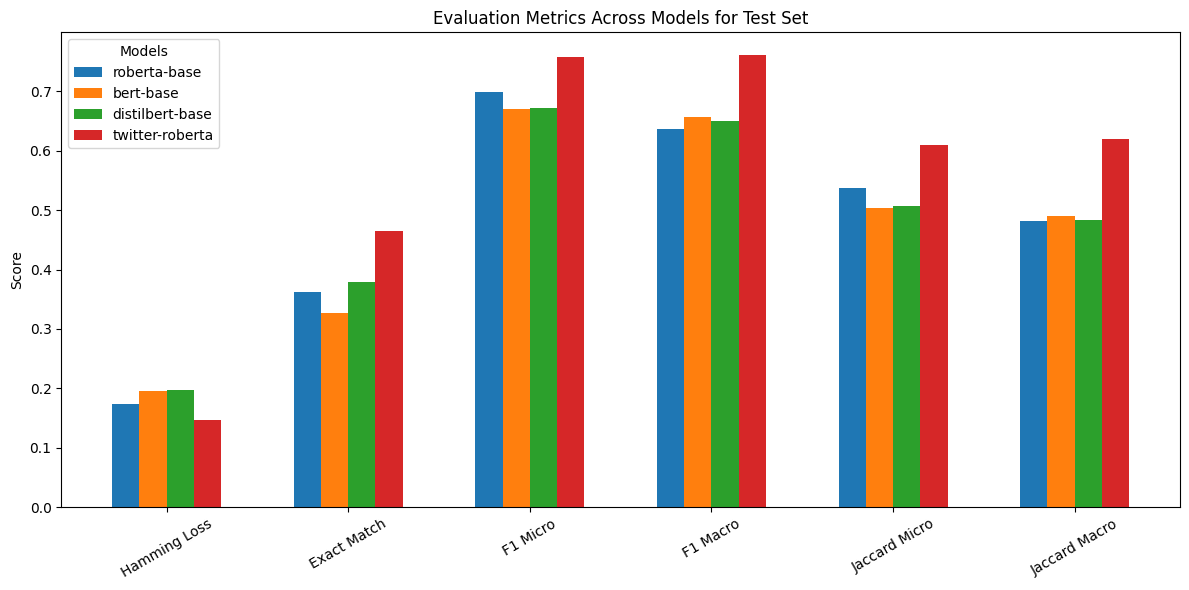

In [19]:
plot_grouped_model_metrics(all_model_metrics)